# Qwen3_small: experiment report

How the final configuration was chosen. Each stage below is one `sweep.py` stage; the
reasoning and the papers each stage tests are in `DECISIONS.md`. All runs are on an Apple
M4 Max (MPS), bf16 autocast, `torch.compile`, 16,384 tokens per optimizer step.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

RUNS = Path("runs")
COLS = ["name", "params_M", "active_params_M", "optim", "lr", "wd", "vocab", "warmup_frac", "best_val_loss", "best_val_bpb",
        "best_step", "steps", "elapsed_min", "steady_tok_s"]

def table(stage, sort="best_val_loss"):
    df = pd.read_csv(RUNS / stage / "summary.csv")
    df["active_params_M"] = df.get("active_params_M", df.params_M).fillna(df.params_M)
    return df[[c for c in COLS if c in df]].sort_values(sort).round(4).reset_index(drop=True)

def curves(run):
    rows = [json.loads(l) for l in open(RUNS / run / "metrics.jsonl")]
    return (pd.DataFrame([r for r in rows if r.get("train_loss") is not None]),
            pd.DataFrame([r for r in rows if "val_loss" in r]))

def plot_val(runs, title, x="step", ax=None, label=lambda r: r.split("/")[-1]):
    ax = ax or plt.subplots(figsize=(8, 4))[1]
    for r in runs:
        _, v = curves(r)
        ax.plot(v[x], v.val_loss, "o-", ms=3, label=label(r))
    ax.set(title=title, xlabel=x, ylabel="validation loss (nats/token)")
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
    return ax

## Stage 0: throughput of the six shapes

30 steps each at seq 512, 8k vocab. Depth costs at most ~30% wall-clock.

In [2]:
tp = table("throughput", sort="steady_tok_s")
tp[["name", "params_M", "steady_tok_s"]].sort_values("steady_tok_s", ascending=False)

,name,params_M,steady_tok_s
5,throughput/classic12,110.1212,15852.8795
4,throughput/wide8,130.0419,14440.9353
3,throughput/deepnarrow,110.4046,12351.5844
2,throughput/levine,114.3948,12152.9139
1,throughput/mlpheavy,146.8266,11943.6666
0,throughput/mobilellm,110.9259,11251.5177


## Stage 1: learning rate, AdamW vs Muon

`mobilellm`, 20k stories × 1 epoch (236 steps), WSD, wd 0.1. The AdamW runs at 5% warmup
(11 steps) stall on the unigram plateau; 20% warmup fixes that.

In [3]:
lr = table("lr")
lr

,name,params_M,active_params_M,optim,lr,wd,vocab,warmup_frac,best_val_loss,best_val_bpb,best_step,steps,elapsed_min,steady_tok_s
0,lr/muon_lr0.004,110.9259,110.9259,muon,0.0040,0.1,8192,0.05,2.3397,0.8184,236,236,6.3067,10419.2020
1,lr/muon_lr0.008,110.9259,110.9259,muon,0.0080,0.1,8192,0.05,2.3549,0.8237,236,236,6.3446,10353.5388
2,lr/muon_lr0.002,110.9259,110.9259,muon,0.0020,0.1,8192,0.05,2.3671,0.8280,236,236,6.2323,10550.3078
3,lr/muon_lr0.001,110.9259,110.9259,muon,0.0010,0.1,8192,0.05,2.4673,0.8630,236,236,6.3835,10288.3389
4,lr/muon_lr0.0005,110.9259,110.9259,muon,0.0005,0.1,8192,0.05,2.6518,0.9276,236,236,6.3102,10413.8128
5,lr/adamw_lr0.0005_wu0.2,110.9259,110.9259,adamw,0.0005,0.1,8192,0.20,2.8129,0.9839,236,236,5.7015,11557.7961
6,lr/adamw_lr0.001_wu0.2,110.9259,110.9259,adamw,0.0010,0.1,8192,0.20,2.8232,0.9875,236,236,5.5455,11898.2167
7,lr/adamw_lr0.00025,110.9259,110.9259,adamw,0.0002,0.1,8192,0.05,2.9884,1.0453,236,236,5.6745,11612.5298
8,lr/adamw_lr0.0005,110.9259,110.9259,adamw,0.0005,0.1,8192,0.05,3.0127,1.0538,236,236,6.1173,10781.4492
9,lr/adamw_lr0.004,110.9259,110.9259,adamw,0.0040,0.1,8192,0.05,3.3334,1.1660,236,236,5.7524,11450.1905


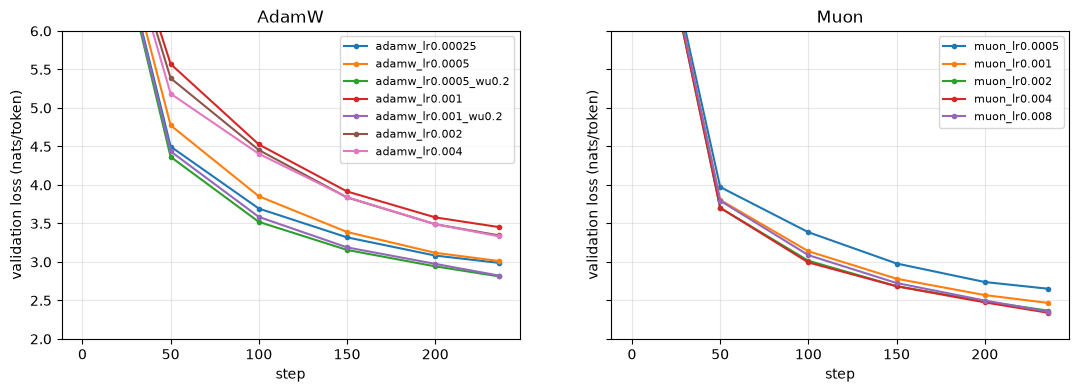

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
names = sorted(p.parent.name for p in (RUNS / "lr").glob("*/summary.json"))
plot_val([f"lr/{n}" for n in names if n.startswith("adamw")], "AdamW", ax=axes[0])
plot_val([f"lr/{n}" for n in names if n.startswith("muon")], "Muon", ax=axes[1])
axes[0].set_ylim(2, 6); plt.show()

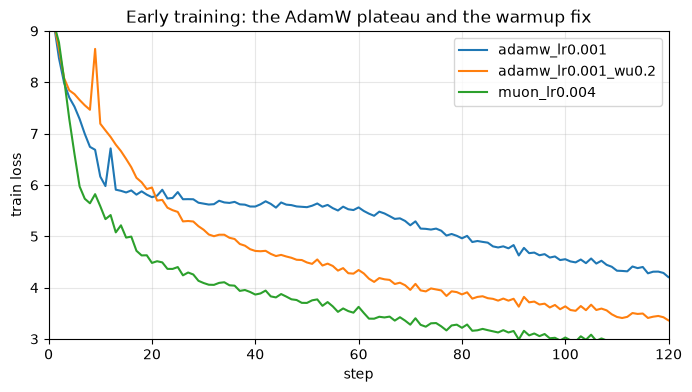

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
for n in ["adamw_lr0.001", "adamw_lr0.001_wu0.2", "muon_lr0.004"]:
    t, _ = curves(f"lr/{n}")
    ax.plot(t.step, t.train_loss, label=n)
ax.set(title="Early training: the AdamW plateau and the warmup fix", xlabel="step", ylabel="train loss",
       xlim=(0, 120), ylim=(3, 9)); ax.grid(alpha=0.3); ax.legend(); plt.show()

## Stage 2: vocabulary 8k vs 16k

`mobilellm`, Muon lr 4e-3, 50k stories × 1 epoch. Compared on bits-per-byte.

In [6]:
table('vocab', sort='best_val_bpb')

,name,params_M,active_params_M,optim,lr,wd,vocab,warmup_frac,best_val_loss,best_val_bpb,best_step,steps,elapsed_min,steady_tok_s
0,vocab/vocab8192,110.9259,110.9259,muon,0.004,0.1,8192,0.1,1.9233,0.6716,592,592,15.7775,10323.6038
1,vocab/vocab16384,115.6445,115.6445,muon,0.004,0.1,16384,0.1,1.9347,0.6716,588,588,16.7968,9942.5089


## Stage 3: model shape

Six presets derived from published depth/width results, all trained on the same 9.7M tokens
(50k stories × 1 epoch), Muon lr 4e-3, 8k vocab. Seed noise was measured by rerunning `levine`
with seed 1.

In [7]:
sh = table("shapes", sort="best_val_bpb")
seed = json.loads((RUNS / "shapes_seed" / "levine_seed1" / "summary.json").read_text())
print(f"levine seed 1: val bpb {seed['best_val_bpb']:.4f} (seed 0: {sh.set_index('name').loc['shapes/levine', 'best_val_bpb']:.4f})")
sh

levine seed 1: val bpb 0.6706 (seed 0: 0.6669)


,name,params_M,active_params_M,optim,lr,wd,vocab,warmup_frac,best_val_loss,best_val_bpb,best_step,steps,elapsed_min,steady_tok_s
0,shapes/levine,114.3948,114.3948,muon,0.004,0.1,8192,0.1,1.9100,0.6669,592,592,15.9264,10218.1285
1,shapes/deepnarrow,110.4046,110.4046,muon,0.004,0.1,8192,0.1,1.9227,0.6714,592,592,16.4621,9895.0091
2,shapes/mobilellm,110.9259,110.9259,muon,0.004,0.1,8192,0.1,1.9245,0.6720,592,592,15.9580,10204.7173
3,shapes/mlpheavy,146.8266,146.8266,muon,0.004,0.1,8192,0.1,1.9311,0.6743,592,592,17.7554,9164.5157
4,shapes/classic12,110.1212,110.1212,muon,0.004,0.1,8192,0.1,1.9404,0.6775,592,592,13.5925,11968.9295
5,shapes/wide8,130.0419,130.0419,muon,0.004,0.1,8192,0.1,1.9712,0.6883,592,592,15.2223,10682.4834


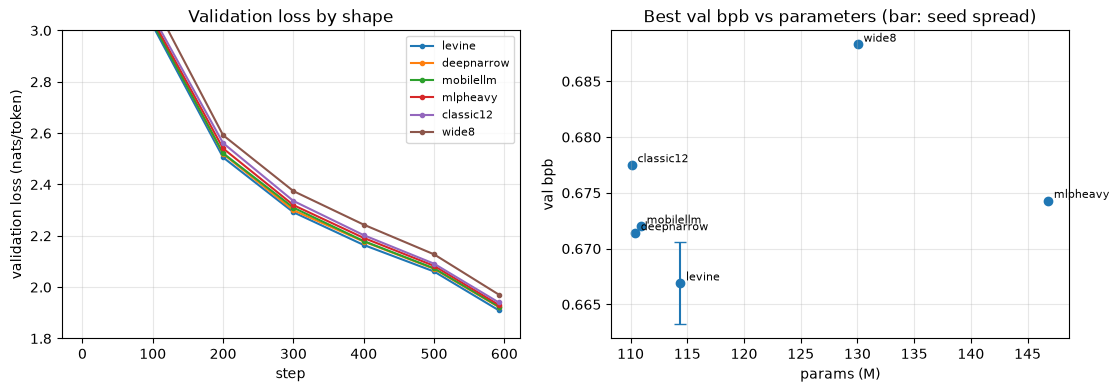

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_val([f"shapes/{n.split('/')[-1]}" for n in sh.name], "Validation loss by shape", ax=axes[0])
axes[0].set_ylim(1.8, 3)
axes[1].scatter(sh.params_M, sh.best_val_bpb)
for r in sh.itertuples():
    axes[1].annotate(r.name.split("/")[-1], (r.params_M, r.best_val_bpb), fontsize=8, xytext=(4, 2), textcoords="offset points")
axes[1].errorbar([sh.params_M[sh.name == "shapes/levine"].item()], [sh.best_val_bpb[sh.name == "shapes/levine"].item()],
                 yerr=abs(seed["best_val_bpb"] - sh.best_val_bpb[sh.name == "shapes/levine"].item()), fmt="none", capsize=4)
axes[1].set(title="Best val bpb vs parameters (bar: seed spread)", xlabel="params (M)", ylabel="val bpb")
axes[1].grid(alpha=0.3); plt.show()

## Stage 4: weight decay in multi-epoch training

`levine`, Muon lr 4e-3, 20k stories × 6 epochs. Low weight decay memorises the training set.

In [9]:
table("wd")

,name,params_M,active_params_M,optim,lr,wd,vocab,warmup_frac,best_val_loss,best_val_bpb,best_step,steps,elapsed_min,steady_tok_s
0,wd/wd1.0,114.3948,114.3948,muon,0.004,1.0,8192,0.1,1.8224,0.6375,1416,1416,38.1489,10163.0665
1,wd/wd0.5,114.3948,114.3948,muon,0.004,0.5,8192,0.1,1.8645,0.6522,1416,1416,38.1242,10169.6868
2,wd/wd2.0,114.3948,114.3948,muon,0.004,2.0,8192,0.1,1.8700,0.6541,1416,1416,36.5969,10597.8682
3,wd/wd0.1,114.3948,114.3948,muon,0.004,0.1,8192,0.1,2.0475,0.7162,900,1416,38.1170,10171.4988


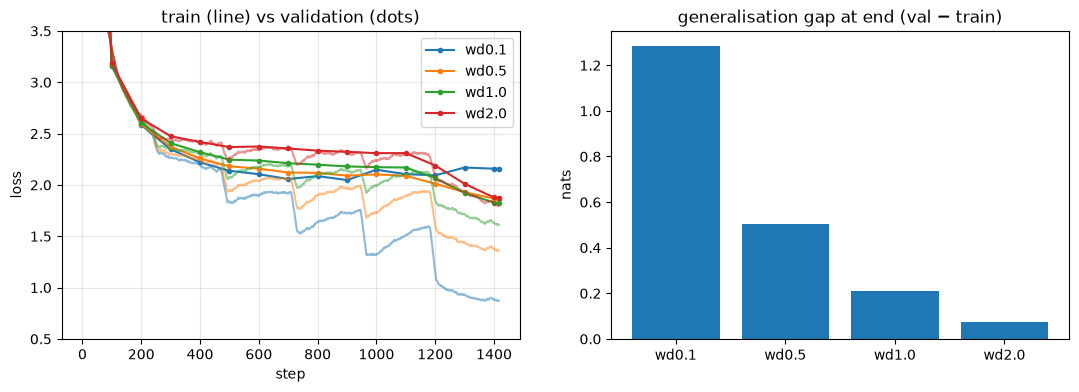

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
wds = sorted((p.parent.name for p in (RUNS / "wd").glob("*/summary.json")), key=lambda n: float(n[2:]))
for n in wds:
    t, v = curves(f"wd/{n}")
    line, = axes[0].plot(t.step, t.train_loss.rolling(20, min_periods=1).mean(), alpha=0.5)
    axes[0].plot(v.step, v.val_loss, "o-", ms=3, color=line.get_color(), label=n)
axes[0].set(title="train (line) vs validation (dots)", xlabel="step", ylabel="loss", ylim=(0.5, 3.5))
axes[0].legend(); axes[0].grid(alpha=0.3)
gap = []
for n in wds:
    t, v = curves(f"wd/{n}")
    gap.append(v.val_loss.iloc[-1] - t.train_loss.iloc[-20:].mean())
axes[1].bar(wds, gap); axes[1].set(title="generalisation gap at end (val − train)", ylabel="nats")
plt.show()

## Stage 5: final runs, AdamW vs Muon at full length

`levine`, 8k vocab, 50k stories, up to 10 epochs with early stopping, best weight decay from stage 4.

In [11]:
final = table("final")
final

,name,params_M,active_params_M,optim,lr,wd,vocab,warmup_frac,best_val_loss,best_val_bpb,best_step,steps,elapsed_min,steady_tok_s
0,final/muon,114.3948,114.3948,muon,0.0040,1.0,8192,0.05,1.5872,0.5542,5920,5920,152.4812,10610.6659
1,final/adamw,114.3948,114.3948,adamw,0.0005,1.0,8192,0.05,1.7466,0.6099,3500,4000,91.0758,12008.8798


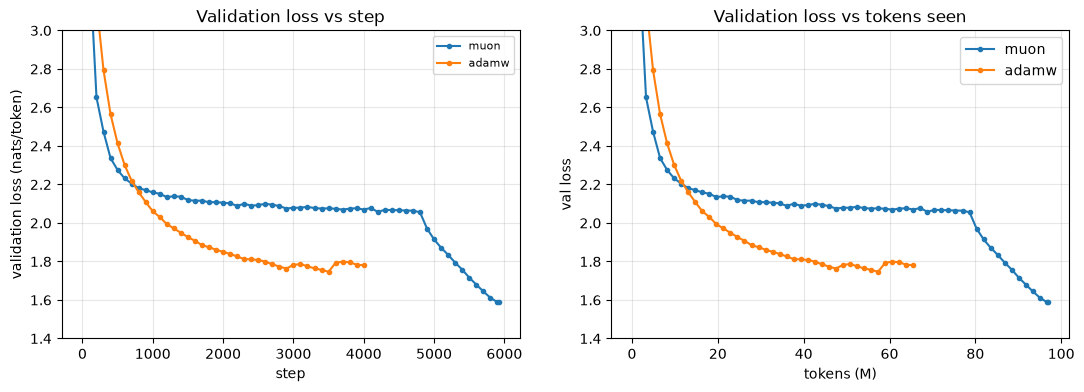

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fn = [f"final/{n.split('/')[-1]}" for n in final.name]
plot_val(fn, "Validation loss vs step", ax=axes[0])
for r in fn:
    _, v = curves(r)
    axes[1].plot(v.tokens / 1e6, v.val_loss, "o-", ms=3, label=r.split("/")[-1])
axes[1].set(title="Validation loss vs tokens seen", xlabel="tokens (M)", ylabel="val loss")
axes[1].grid(alpha=0.3); axes[1].legend()
for ax in axes: ax.set_ylim(1.4, 3)
plt.show()

In [13]:
# tokens each optimizer needed to reach the other's best validation loss
v = {r.split("/")[-1]: curves(r)[1] for r in fn}
if {"adamw", "muon"} <= set(v):
    target = v["adamw"].val_loss.min()
    reach = v["muon"][v["muon"].val_loss <= target]
    if len(reach):
        ta = v["adamw"].tokens[v["adamw"].val_loss.idxmin()]
        tm = reach.tokens.iloc[0]
        print(f"AdamW best {target:.4f} at {ta / 1e6:.1f}M tokens; Muon reaches it at {tm / 1e6:.1f}M tokens -> {ta / tm:.2f}x fewer tokens")
    print(f"best val loss: AdamW {v['adamw'].val_loss.min():.4f} | Muon {v['muon'].val_loss.min():.4f}")

AdamW best 1.7466 at 57.3M tokens; Muon reaches it at 90.1M tokens -> 0.64x fewer tokens
best val loss: AdamW 1.7466 | Muon 1.5872


## Stage 6: classifier ablations

Sentiment (2-class) and emotion (6-class) on the same deduplicated, stratified test split.

In [14]:
base = json.loads((RUNS / "cls" / "baselines.json").read_text())
rows = [{"run": k, "test_acc": v["test_acc"], "test_macro_f1": v["test_macro_f1"]} for k, v in base.items()]
for p in sorted((RUNS / "cls").glob("*/result.json")):
    r = json.loads(p.read_text())
    rows.append({"run": r["name"], "test_acc": r["test_acc"], "test_macro_f1": r["test_macro_f1"],
                 "ckpt": r["ckpt"], "lr": r["lr"]})
pd.DataFrame(rows).round(4)

,run,test_acc,test_macro_f1,ckpt,lr
0,sentiment_majority,0.5485,0.3542,NaN,NaN
1,sentiment_tfidf_lr,0.9386,0.9380,NaN,NaN
2,emotion_majority,0.3350,0.0836,NaN,NaN
3,emotion_tfidf_lr,0.8660,0.8409,NaN,NaN
4,100k_emotion_full_last,0.9230,0.8968,runs/final100k/muon/best.pt,0.0
5,100k_sentiment_full_last,0.9750,0.9747,runs/final100k/muon/best.pt,0.0
6,100k_sentiment_probe_last,0.7120,0.7091,runs/final100k/muon/best.pt,0.0
7,emotion_full_last,0.9280,0.9044,runs/final/muon/best.pt,0.0
8,sentiment_full_last,0.9737,0.9735,runs/final/muon/best.pt,0.0
9,sentiment_full_mean,0.9674,0.9671,runs/final/muon/best.pt,0.0


## Stage 7: Qwen3-MoE variants of `levine`

Every SwiGLU replaced by a routed mixture of SwiGLU experts (as in Qwen3-30B-A3B), with a Switch
load-balancing loss (0.01). Each protocol reuses an existing dense run as reference: 50k × 1 epoch
(`shapes/levine`) and 20k × 6 epochs with wd 1.0 (`wd/wd1.0`). Reasoning and citations: `DECISIONS.md` §8.

In [15]:
moe = table("moe", sort="best_val_bpb")
dense = pd.concat([table("shapes").query("name == 'shapes/levine'"), table("wd").query("name == 'wd/wd1.0'")])
pd.concat([dense, moe]).reset_index(drop=True)

,name,params_M,active_params_M,optim,lr,wd,vocab,warmup_frac,best_val_loss,best_val_bpb,best_step,steps,elapsed_min,steady_tok_s
0,shapes/levine,114.3948,114.3948,muon,0.004,0.1,8192,0.1,1.9100,0.6669,592,592,15.9264,10218.1285
1,wd/wd1.0,114.3948,114.3948,muon,0.004,1.0,8192,0.1,1.8224,0.6375,1416,1416,38.1489,10163.0665
2,moe/moe_cap_6ep,194.1439,74.7045,muon,0.004,1.0,8192,0.1,1.8227,0.6375,1416,1416,57.1049,6792.4434
3,moe/moe_cap_6ep_edrop0.4,194.1439,74.7045,muon,0.004,1.0,8192,0.1,1.8527,0.6480,1416,1416,55.4747,7061.7230
4,moe/moe_cap_1ep,194.1439,74.7045,muon,0.004,0.1,8192,0.1,1.9112,0.6673,592,592,24.2780,6744.8629
5,moe/moe_cap_fine_1ep,194.5125,75.0732,muon,0.004,0.1,8192,0.1,1.9278,0.6731,592,592,27.3279,6013.9848
6,moe/moe_matched_1ep,114.5176,54.7980,muon,0.004,0.1,8192,0.1,1.9283,0.6733,592,592,16.6923,9849.7001


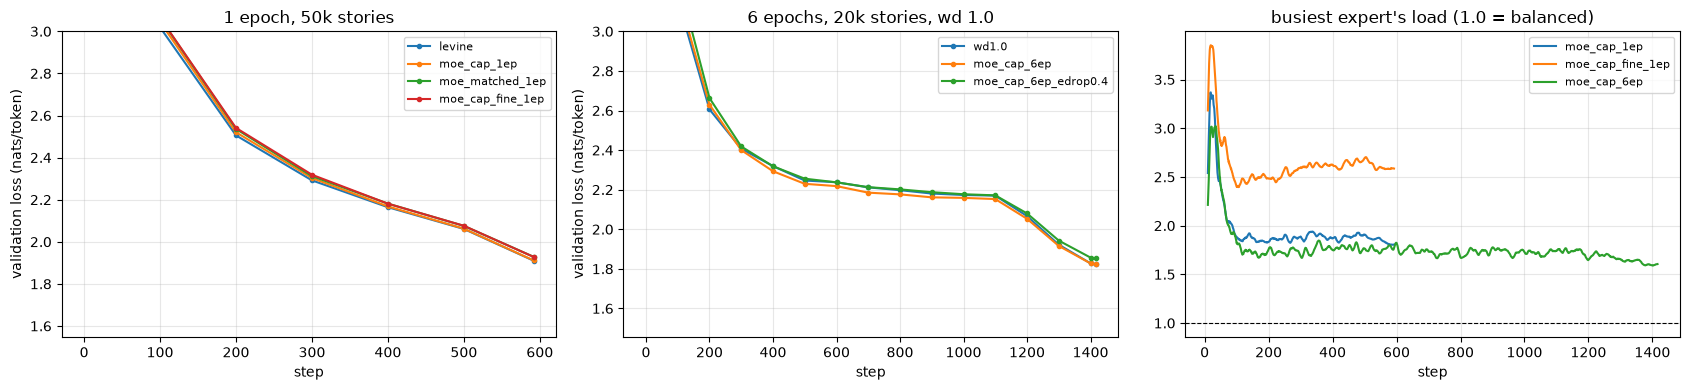

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
plot_val(["shapes/levine", "moe/moe_cap_1ep", "moe/moe_matched_1ep", "moe/moe_cap_fine_1ep"],
         "1 epoch, 50k stories", ax=axes[0])
plot_val(["wd/wd1.0", "moe/moe_cap_6ep", "moe/moe_cap_6ep_edrop0.4"], "6 epochs, 20k stories, wd 1.0", ax=axes[1])
for r in ["moe/moe_cap_1ep", "moe/moe_cap_fine_1ep", "moe/moe_cap_6ep"]:
    t, _ = curves(r)
    axes[2].plot(t.step, t.moe_max_load.rolling(10).mean(), label=r.split("/")[-1])
axes[2].axhline(1, color="k", lw=0.8, ls="--")
axes[2].set(title="busiest expert's load (1.0 = balanced)", xlabel="step"); axes[2].grid(alpha=0.3); axes[2].legend(fontsize=8)
for ax in axes[:2]: ax.set_ylim(top=3.0)
plt.tight_layout()

In [17]:
# train/val gap at the end of each 6-epoch run: how much the extra experts memorise
for r in ["wd/wd1.0", "moe/moe_cap_6ep", "moe/moe_cap_6ep_edrop0.4"]:
    t, v = curves(r)
    tr = t.train_loss.tail(20).mean()
    print(f"{r:28s} train {tr:.4f} | val {v.val_loss.iloc[-1]:.4f} | gap {v.val_loss.iloc[-1] - tr:+.3f}")

wd/wd1.0                     train 1.6128 | val 1.8224 | gap +0.210
moe/moe_cap_6ep              train 1.5612 | val 1.8227 | gap +0.261


moe/moe_cap_6ep_edrop0.4     train 1.7009 | val 1.8527 | gap +0.152


## Stage 8: the final recipe on 100k stories

Same model and recipe as `final/muon`, twice the unique stories (above the spec range). The
periodic eval windows and `val50k_*` both use the 50k run's val set, so the curves compare directly.

In [18]:
s50 = json.loads((RUNS / "final" / "muon" / "summary.json").read_text())
s100 = json.loads((RUNS / "final100k" / "muon" / "summary.json").read_text())
pd.DataFrame([{"run": "50k x 10 ep", "val_loss (50k val set)": s50["full_val_loss"], "bpb": s50["full_val_bpb"],
               "tokens_M": s50["tokens_seen"] / 1e6, "minutes": s50["elapsed_min"]},
              {"run": "100k x 10 ep", "val_loss (50k val set)": s100["val50k_loss"], "bpb": s100["val50k_bpb"],
               "tokens_M": s100["tokens_seen"] / 1e6, "minutes": s100["elapsed_min"]}]).round(4)

,run,val_loss (50k val set),bpb,tokens_M,minutes
0,50k x 10 ep,1.5738,0.5495,96.9933,152.4812
1,100k x 10 ep,1.4899,0.5202,192.3482,305.2602


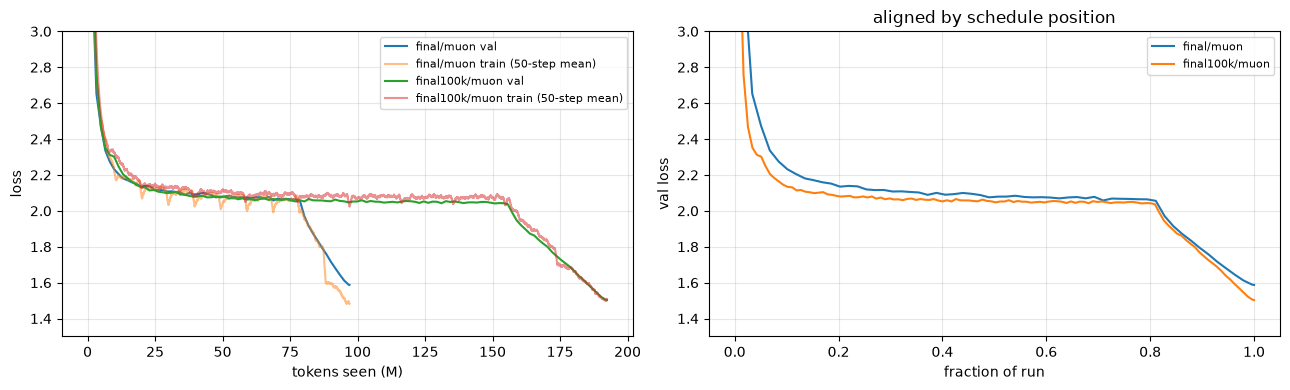

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for r in ["final/muon", "final100k/muon"]:
    t, v = curves(r)
    axes[0].plot(v.tokens / 1e6, v.val_loss, label=f"{r} val")
    axes[0].plot(t.tokens / 1e6, t.train_loss.rolling(50).mean(), alpha=0.5, label=f"{r} train (50-step mean)")
    axes[1].plot(v.step / v.step.max(), v.val_loss, label=r)
axes[0].set(xlabel="tokens seen (M)", ylabel="loss", ylim=(1.3, 3)); axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)
axes[1].set(xlabel="fraction of run", ylabel="val loss", ylim=(1.3, 3), title="aligned by schedule position"); axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)
plt.tight_layout()